In [50]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import scipy.stats as stats

In [2]:
def discount(r, T):

    return np.exp( - r * T )

def time_step(T):

    return np.sqrt( T )

def d_1(S0, K, r, sigma, T):

    return ( np.log( S0 / K ) + ( r + sigma ** 2 / 2 ) * T ) / ( sigma * time_step(T) )

def d_2(S0, K, r, sigma, T):

    return d_1(S0, K, r, sigma, T) - sigma * time_step(T)

def bsm_call(S0, K, r, sigma, T):
    """
    Black-Scholes-Merton analytical price for European call option.
    """
    
    N1, N2 = sp.stats.norm.cdf( d_1(S0, K, r, sigma, T) ), sp.stats.norm.cdf( d_2(S0, K, r, sigma, T) )
    
    return S0 * N1 - K * discount(r, T) * N2

def bsm_put(S0, K, r, sigma, T):
    """
    Black-Scholes-Merton analytical price for European put option.
    """
    
    N1, N2 = sp.stats.norm.cdf( d_1(S0, K, r, sigma, T) ), sp.stats.norm.cdf( d_2(S0, K, r, sigma, T) )
    
    return K * discount(r, T) * ( 1 - N2 ) - S0 * ( 1 - N1 )

In [28]:
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20

print("Call:", f"{bsm_call(S0, K, r, sigma, T):.4f}")
print("Put: ", f"{bsm_put(S0, K, r, sigma, T):.4f}")
print("")
print("Put-Call Parity:", np.isclose(bsm_call(S0, K, r, sigma, T) - bsm_put(S0, K, r, sigma, T), S0 - K * discount(r, T)), sep='\n')

Call: 10.4506
Put:  5.5735

Put-Call Parity:
True


In [27]:
S0 = 105.0
K = 100.0
T = 0.5
r = 0.03
sigma = 0.25

print("Call:", f"{bsm_call(S0, K, r, sigma, T):.4f}")
print("Put: ", f"{bsm_put(S0, K, r, sigma, T):.4f}")
print("")
print("Put-Call Parity:", np.isclose(bsm_call(S0, K, r, sigma, T) - bsm_put(S0, K, r, sigma, T), S0 - K * discount(r, T)), sep='\n')

Call: 10.8715
Put:  4.3827

Put-Call Parity:
True


In [36]:
def prob_exercise(S0, K, r, sigma, T):

    return sp.stats.norm.cdf( d_2(S0, K, r, sigma, T) )

def binary_call(S0, K, r, sigma, T, Q):

    return discount(r, T) * Q * prob_exercise(S0, K, r, sigma, T)

In [38]:
S0 = 100.0
K = np.array([90.0, 100.0, 110.0])
T = 1.0
r = 0.05
sigma = 0.20
Q = 10

print("The probability of exercise is: ", prob_exercise(S0, K, r, sigma, T))
print("Binary Call Price: ", f"{binary_call(S0, 100, r, sigma, T, Q):.4f}")

The probability of exercise is:  [0.75073439 0.55961769 0.37200379]
Binary Call Price:  5.3232


In [39]:
def stock_mean(S0, r, T):

    return S0 * np.exp( r * T )

def stock_median(S0, r, sigma, T):

    return S0 * np.exp( ( r - 0.5 * sigma ** 2 ) * T )

def prob_above(S0, K, r, sigma, T):

    return prob_exercise(S0, K, r, sigma, T)

In [49]:
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20

print("The mean of a stock:", f"{stock_mean(S0, r, T):.2f}")
print("")
print("The median of a stock:", f"{stock_median(S0, r, sigma, T):.2f}")
print("")
print("The probability that ST > 120:", f"{prob_above(S0, 120, r, sigma, T) * 100:.1f}", "%")
print("")
print("The probability that ST < 80:", f"{(1 - prob_above(S0, 80, r, sigma, T)) * 100:.1f}", "%")
print("")
print("The probability that ST > mean(ST):", f"{prob_above(S0, stock_mean(S0, r, T), r, sigma, T) * 100:.1f}", "%")

The mean of a stock: 105.13

The median of a stock: 103.05

The probability that ST > 120: 22.3 %

The probability that ST < 80: 10.3 %

The probability that ST > mean(ST): 46.0 %


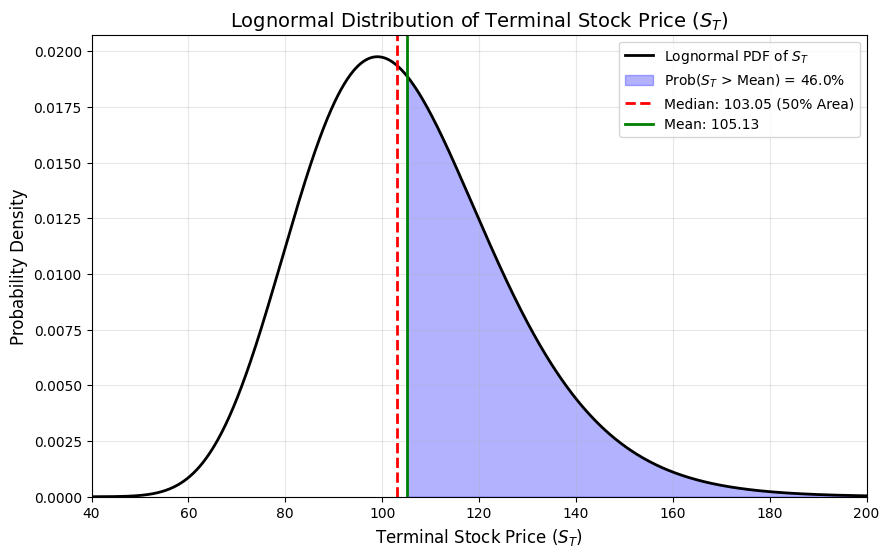

In [52]:
S0 = 100.0
r = 0.05
sigma = 0.20
T = 1.0

# 2. Define the lognormal distribution parameters for S_T
# The underlying normal distribution Z has mean mu_log and std dev sigma_log
mu_log = np.log(S0) + (r - 0.5 * sigma**2) * T
sigma_log = sigma * np.sqrt(T)

# 3. Calculate the theoretical mean and median
mean_ST = stock_mean(S0, r, T)
median_ST = stock_median(S0, r, sigma, T)

# 4. Generate data points for the x-axis (possible stock prices)
x = np.linspace(40, 200, 1000)

# 5. Generate the Probability Density Function (PDF) 
# SciPy's lognorm uses 's' for shape (sigma) and 'scale' for exp(mu)
pdf = stats.lognorm.pdf(x, s=sigma_log, scale=np.exp(mu_log))

# 6. Initialize the plot
plt.figure(figsize=(10, 6))
plt.plot(x, pdf, color='black', linewidth=2, label='Lognormal PDF of $S_T$')

# 7. Fill the area where S_T > mean (to visualize the 46.0% probability)
plt.fill_between(x, pdf, where=(x > mean_ST), color='blue', alpha=0.3, label='Prob($S_T$ > Mean) = 46.0%')

# 8. Add vertical lines for the Mean and Median
plt.axvline(median_ST, color='red', linestyle='--', linewidth=2, label=f'Median: {median_ST:.2f} (50% Area)')
plt.axvline(mean_ST, color='green', linestyle='-', linewidth=2, label=f'Mean: {mean_ST:.2f}')

# 9. Format the plot with labels and legend
plt.title('Lognormal Distribution of Terminal Stock Price ($S_T$)', fontsize=14)
plt.xlabel('Terminal Stock Price ($S_T$)', fontsize=12)
plt.ylabel('Probability Density', fontsize=12)
plt.legend(loc='upper right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.xlim(40, 200)
plt.ylim(bottom=0)

# 10. Display the plot
plt.show()